## 1. Import Libraries, Configuration, and Utilities
Here we import libraries, and define constants used
throughout the notebook. We also define utility functions for model.

### 1.1. Import Libraries

In [47]:
# Import necessary libraries
import matplotlib.pyplot as plt
# NLP and preprocessing
import nltk
import numpy as np
import pandas as pd
# Deep learning
import torch
# Machine learning
from sklearn.metrics import (classification_report, hamming_loss, f1_score, jaccard_score)
from transformers import AutoTokenizer, AutoModelForSequenceClassification

In [48]:
# Download necessary NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('stopwords')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /Users/hsamadov/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/hsamadov/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/hsamadov/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/hsamadov/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/hsamadov/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [49]:
# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### 1.2. Configuration Parameters

In [50]:
TEST_DATA_PATH = 'data/track-a-test.csv'

In [51]:
# Emotion labels we're predicting
EMOTIONS = ['anger', 'fear', 'joy', 'sadness', 'surprise']

In [53]:
# Define model paths and data path
MODELS = {
    'roberta-base': './results/roberta-base_vanilla_out',
    'bert-base': './results/bert-base-uncased_vanilla_out',
    'distilbert-base': './results/distilbert-base-uncased_vanilla_out',
    'twitter-roberta': './results/twitter-roberta-base-emotion-multilabel-latest_vanilla_out'
}

## 2. Data Loading & Quick EDA

In [55]:
# Load the dataset
df = pd.read_csv(TEST_DATA_PATH)

# Display the first few rows to understand the data structure
df.head()

,id,text,anger,fear,joy,sadness,surprise
0,eng_test_track_a_00001,/ o \ So today I went in for a new exam with D...,NaN,NaN,NaN,NaN,NaN
1,eng_test_track_a_00002,The image I have in my mind is this: a group o...,NaN,NaN,NaN,NaN,NaN
2,eng_test_track_a_00003,"I slammed my fist against the door and yelled,...",NaN,NaN,NaN,NaN,NaN
3,eng_test_track_a_00004,I could not unbend my knees.,NaN,NaN,NaN,NaN,NaN
4,eng_test_track_a_00005,"I spent the night at the hotel, mostly hanging...",NaN,NaN,NaN,NaN,NaN


In [56]:
texts = df['text'].tolist()

## 4. Model Comparison

In [60]:
def compute_metrics(y_true, y_pred, threshold=0.5, verbose=False):
    if not isinstance(y_pred[0][0], (np.int64, np.int32, int, bool)):
        y_pred_binary = (y_pred >= threshold).astype(int)
    else:
        y_pred_binary = y_pred

    metrics = {
        "hamming_loss": hamming_loss(y_true, y_pred_binary),
        "exact_match": np.all(y_true == y_pred_binary, axis=1).mean(),
        "f1_micro": f1_score(y_true, y_pred_binary, average="micro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred_binary, average="macro", zero_division=0),
        "jaccard_micro": jaccard_score(y_true, y_pred_binary, average="micro", zero_division=0),
        "jaccard_macro": jaccard_score(y_true, y_pred_binary, average="macro", zero_division=0)
    }

    if verbose:
        print(classification_report(y_true, y_pred_binary, target_names=EMOTIONS, zero_division=0))
        print(f"Exact Match Accuracy: {metrics['exact_match']:.4f}")

    return metrics

In [57]:
def predict(model_dir, texts, batch_size=32):
    tokenizer = AutoTokenizer.from_pretrained(model_dir)
    model = AutoModelForSequenceClassification.from_pretrained(model_dir)
    model.to(device)
    model.eval()

    all_preds = []

    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch_texts = texts[i:i+batch_size]
            encodings = tokenizer(batch_texts, padding=True, truncation=True, return_tensors="pt").to(device)
            outputs = model(**encodings)
            logits = outputs.logits
            probs = torch.sigmoid(logits).cpu().numpy()
            all_preds.append(probs)

    return np.vstack(all_preds)


In [58]:
all_model_preds = {}
all_model_metrics = {}

In [59]:
for name, model_path in MODELS.items():
    print(f"Running model: {model_path}")
    preds = predict(model_path, texts)
    all_model_preds[name] = preds


Running model: ./results/roberta-base_vanilla_out
Running model: ./results/bert-base-uncased_vanilla_out
Running model: ./results/distilbert-base-uncased_vanilla_out
Running model: ./results/twitter-roberta-base-emotion-multilabel-latest_vanilla_out


In [64]:
# Example if true labels are in the test set (currently they're NaN)
# true_labels = df_test[EMOTIONS].values.astype(int)

# OR if loaded separately:
# true_labels = np.load("ground_truth.npy")

for model_name, y_pred in all_model_preds.items():
    print(f"\nEvaluating {model_name}")
    metrics = compute_metrics(true_labels, y_pred, threshold=0.5, verbose=True)
    all_model_metrics[model_name] = metrics



Evaluating roberta-base
              precision    recall  f1-score   support

       anger       0.00      0.00      0.00         0
        fear       0.00      0.00      0.00         0
         joy       0.00      0.00      0.00         0
     sadness       0.00      0.00      0.00         0
    surprise       0.00      0.00      0.00         0

   micro avg       0.00      0.00      0.00         0
   macro avg       0.00      0.00      0.00         0
weighted avg       0.00      0.00      0.00         0
 samples avg       0.00      0.00      0.00         0

Exact Match Accuracy: 0.1428

Evaluating bert-base
              precision    recall  f1-score   support

       anger       0.00      0.00      0.00         0
        fear       0.00      0.00      0.00         0
         joy       0.00      0.00      0.00         0
     sadness       0.00      0.00      0.00         0
    surprise       0.00      0.00      0.00         0

   micro avg       0.00      0.00      0.00         0
 

In [67]:
print(all_model_metrics)

{'roberta-base': {'hamming_loss': 0.2748825442717745, 'exact_match': np.float64(0.14275388507408746), 'f1_micro': 0.0, 'f1_macro': 0.0, 'jaccard_micro': 0.0, 'jaccard_macro': 0.0}, 'bert-base': {'hamming_loss': 0.2954101915431876, 'exact_match': np.float64(0.117455728225515), 'f1_micro': 0.0, 'f1_macro': 0.0, 'jaccard_micro': 0.0, 'jaccard_macro': 0.0}, 'distilbert-base': {'hamming_loss': 0.2880375858330322, 'exact_match': np.float64(0.10480664980122877), 'f1_micro': 0.0, 'f1_macro': 0.0, 'jaccard_micro': 0.0, 'jaccard_macro': 0.0}, 'twitter-roberta': {'hamming_loss': 0.3019877123238164, 'exact_match': np.float64(0.08818214672930973), 'f1_micro': 0.0, 'f1_macro': 0.0, 'jaccard_micro': 0.0, 'jaccard_macro': 0.0}}


## 5. Plotting Model Metrics

In [65]:
def plot_grouped_model_metrics(metrics_dict):
    """
    Plots grouped bar charts to compare models across multiple evaluation metrics.

    Parameters:
        metrics_dict (dict): Dictionary with model names as keys and metric sub-dicts as values.
        Example:
            {
                'model1': {'f1_micro': 0.72, ...},
                'model2': {'f1_micro': 0.68, ...},
            }
    """
    metric_names = list(next(iter(metrics_dict.values())).keys())
    model_names = list(metrics_dict.keys())

    n_metrics = len(metric_names)
    n_models = len(model_names)
    bar_width = 0.15
    x = np.arange(n_metrics)

    plt.figure(figsize=(12, 6))

    for i, model in enumerate(model_names):
        values = [metrics_dict[model][metric] for metric in metric_names]
        plt.bar(x + i * bar_width, values, width=bar_width, label=model)

    plt.xticks(x + bar_width * (n_models - 1) / 2, [m.replace('_', ' ').title() for m in metric_names], rotation=30)
    plt.ylabel("Score")
    plt.title("Evaluation Metrics Across Models")
    plt.legend(title="Models")
    plt.tight_layout()
    plt.show()


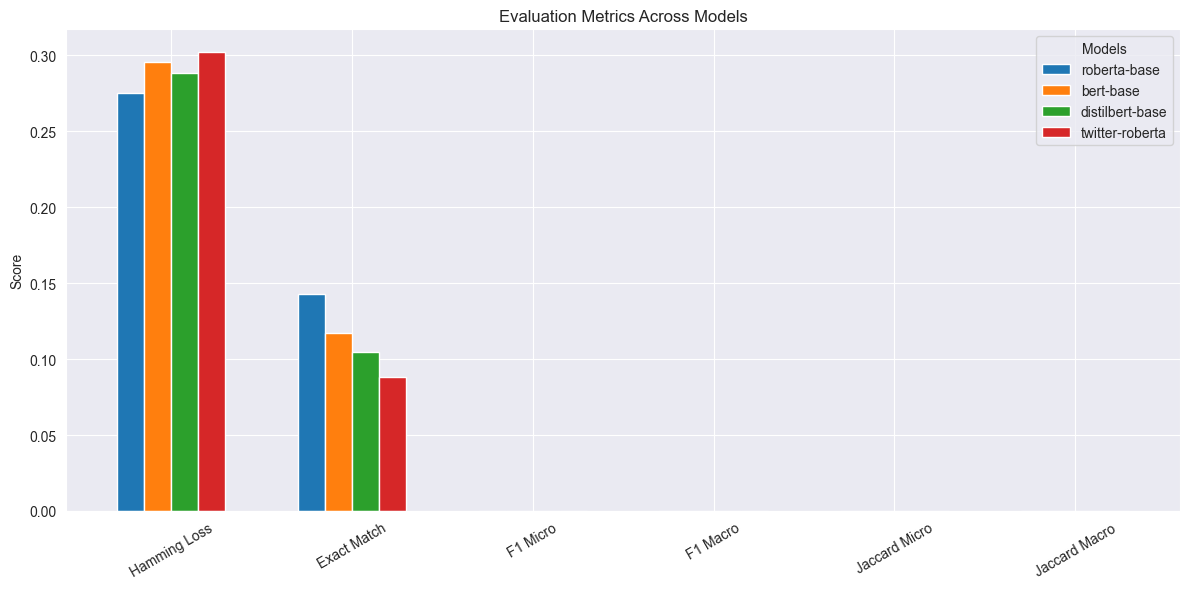

In [68]:
plot_grouped_model_metrics(all_model_metrics)
